*******DATA ANALYSIS PROJECT DECODELABS INTERNSHIP TASK 2*******

****TASK:1****

**IMPORT LIBRARIES**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

***LOAD CSV FILE***

In [2]:
df=pd.read_csv("C:/Users/NCS B1/Downloads/Dataset for Data Analytics.csv")

***SHOW FIRST ROWS***

In [3]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [4]:
print("rows",df.shape[0])
print("columns",df.shape[1])

rows 1200
columns 14


***IDENTIFY MISSING VALUES***

In [5]:
missing=df.isnull().sum()
print(missing)

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64


In [6]:
#FILL MISSING VALUES
df['CouponCode']=df['CouponCode'].fillna('NoCoupon')

In [7]:
#CHECK MISSING VALUES AFTER FILLING
print(df['CouponCode'].isna().sum())

0


***FIND DUPLICATE RECORDS***

In [8]:
duplicated=df.duplicated().sum()
print("duplicate records are ",duplicated)

duplicate records are  0


***CORRECT DATA FORMATS***

In [9]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   str    
 1   Date             1200 non-null   str    
 2   CustomerID       1200 non-null   str    
 3   Product          1200 non-null   str    
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   str    
 7   PaymentMethod    1200 non-null   str    
 8   OrderStatus      1200 non-null   str    
 9   TrackingNumber   1200 non-null   str    
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       1200 non-null   str    
 12  ReferralSource   1200 non-null   str    
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), str(10)
memory usage: 229.1 KB
None


In [10]:
#DATE DATA TYPE IS SET TO AS DATE 
df['Date']=pd.to_datetime(df['Date'],errors="coerce")

****STANDARDIZE TEXT****

In [11]:
text_columns=df.select_dtypes(include="str").columns

for col in text_columns:
    df[col]=df[col].apply(
        lambda x: x.strip()
        if isinstance(x, str)
        else x
    )

***VALIDATE IDs***

In [12]:
#CHECK INVALID ORDERIDs
invalid_order_id=~df['OrderID'].astype(str).str.fullmatch(r"ORD\d{6}")
print(invalid_order_id.sum())

0


In [13]:
#CHECK INVALID CUSTOMER IDs
invalid_customer_id=~df['CustomerID'].astype(str).str.fullmatch(r"C\d{5}")
print(invalid_customer_id.sum())

0


In [14]:
#CHECK INVALID TRACKING NUMBER
invalid_tracking=~df['TrackingNumber'].astype(str).str.fullmatch(r"TRK\d{8}")
print(invalid_tracking.sum())

0


***VALIDATE NUMERICAL VALUES***

In [15]:
#VALIDATE QUANTITY 
invalid_quantity=~df['Quantity'].between(1,5)
print(invalid_quantity.sum())

0


In [16]:
#VALIDATE UNIT PRICE
invalid_price=df['UnitPrice']<=0
print(invalid_price.sum())

0


In [17]:
#VALIDATE ITEMS IN CART
invalid_cart=~df['ItemsInCart'].between(1,10)
print(invalid_cart.sum())

0


In [18]:
#VALIDATE TOTAL PRICE
invalid_total=~df['TotalPrice'].gt(0)
print(invalid_total.sum())

0


***BUSINESS RULE VALIDATION***

In [19]:
#CALCULATE EXPECTED TOTAL
expected_total=df['Quantity']*df["UnitPrice"]

In [20]:
#COMPARE WITH EXISTING TOTALPRICE
mismatch=(abs(df['TotalPrice']- expected_total) > 0.01)
print("TotalPrice calculation mismatches:",mismatch.sum())

TotalPrice calculation mismatches: 0


****BASIC STATISTICS****

In [21]:
print(df.describe())

                      Date     Quantity    UnitPrice  ItemsInCart   TotalPrice
count                 1200  1200.000000  1200.000000  1200.000000  1200.000000
mean   2024-03-22 16:58:48     2.945833   356.412750     5.485000  1053.968300
min    2023-01-01 00:00:00     1.000000    11.390000     1.000000    11.390000
25%    2023-08-03 18:00:00     2.000000   186.062500     4.000000   410.520000
50%    2024-03-23 00:00:00     3.000000   364.210000     5.000000   823.615000
75%    2024-11-08 12:00:00     4.000000   521.570000     7.000000  1578.475000
max    2025-06-30 00:00:00     5.000000   699.930000    10.000000  3456.400000
std                    NaN     1.407557   197.177146     2.281983   819.856558


****DATA DISTRIBUTION****

Text(0, 0.5, 'frequency')

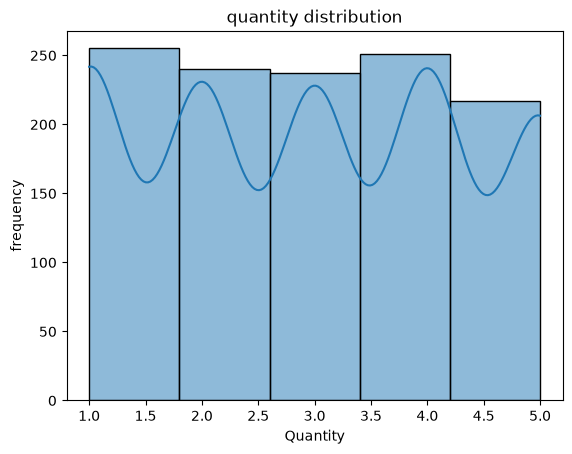

In [22]:
#QUANTITY DISTRIBUTION
plt.Figure(figsize=(8,5))
sns.histplot(df['Quantity'],kde=True,bins=5)
plt.title("quantity distribution")
plt.xlabel("Quantity")
plt.ylabel("frequency")

Text(0, 0.5, 'frequency')

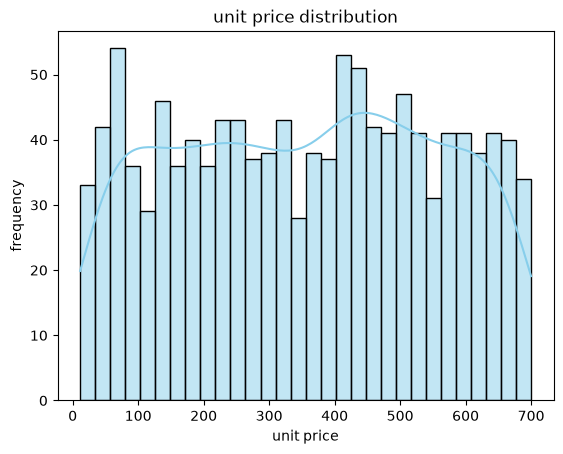

In [23]:
#Unit price distribution
plt.Figure(figsize=(8,5))
sns.histplot(df['UnitPrice'],kde=True,bins=30,color='skyblue')
plt.title("unit price distribution")
plt.xlabel("unit price")
plt.ylabel("frequency")

Text(0, 0.5, 'frequency')

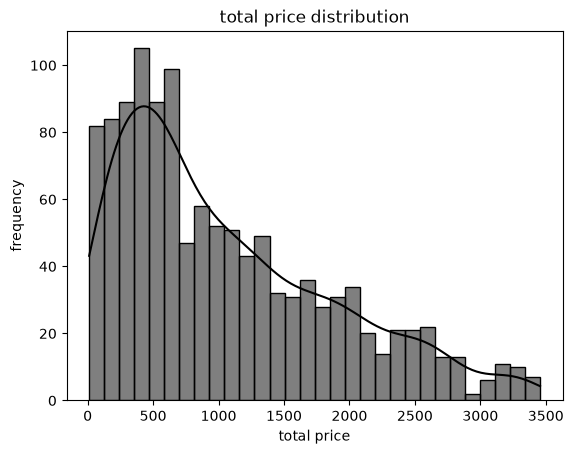

In [24]:
#total price distribution
plt.Figure(figsize=(8,5))
sns.histplot(df['TotalPrice'],kde=True,bins=30,color="black")
plt.title("total price distribution")
plt.xlabel("total price")
plt.ylabel("frequency")

Text(0, 0.5, 'frequency')

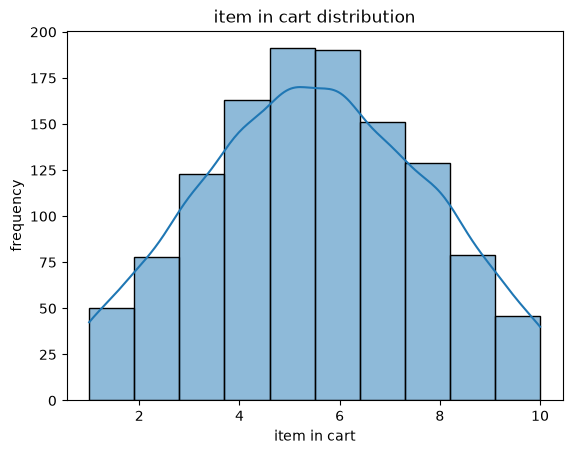

In [25]:
#item in cart distribution
plt.Figure(figsize=(8,5))
sns.histplot(df['ItemsInCart'],kde=True,bins=10)
plt.title("item in cart distribution")
plt.xlabel("item in cart")
plt.ylabel("frequency")

****IDENTIFY TRENDS****

In [26]:
#CREATE YEAR
df['year']=df['Date'].dt.year

In [27]:
#create month
df['month']=df['Date'].dt.month

In [28]:
#create month name
df['MonthName']=df['Date'].dt.strftime("%b")

In [29]:
#create day
df['day']=df['Date'].dt.day

In [30]:
#create day name
df['DayName']=df['Date'].dt.strftime("%a")

In [31]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,year,month,MonthName,day,DayName
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,2023,1,Jan,4,Wed
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,2024,8,Aug,23,Fri
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2024,2,Feb,27,Tue
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,2023,10,Oct,15,Sun
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,2025,5,May,8,Thu


*MONTHLY ORDERS TREND*

Text(0, 0.5, 'number of orders')

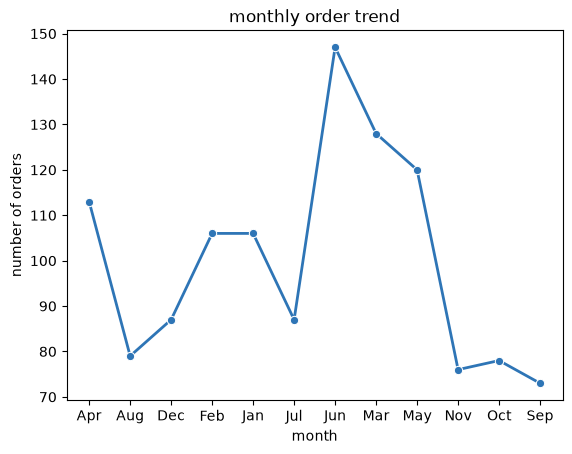

In [32]:
monthly_orders=df.groupby('MonthName')['OrderID'].count()
plt.Figure(figsize=(16,8))
sns.lineplot(x=monthly_orders.index,y=monthly_orders.values,color='#2e75b6',marker="o",linewidth=2)
plt.title("monthly order trend")
plt.xlabel("month")
plt.ylabel("number of orders")

*MONTHLY REVENUE TREND*

Text(0, 0.5, 'revenue')

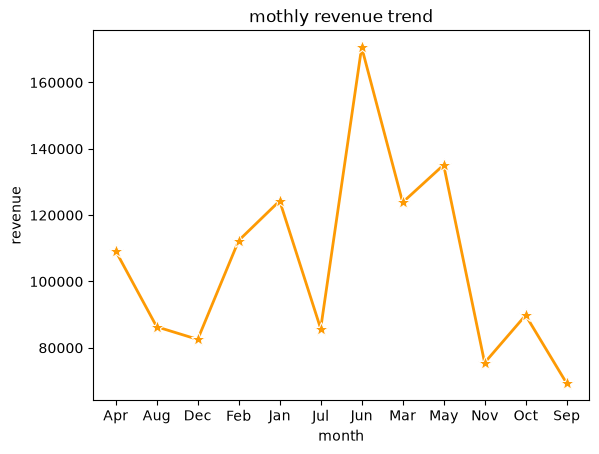

In [33]:
monthly_revenue=df.groupby("MonthName")['TotalPrice'].sum()
plt.Figure(figsize=(16,9))
sns.lineplot(x=monthly_revenue.index,y=monthly_revenue.values,color="#FD9A04",marker="*",linewidth=2,markersize=10)
plt.title("mothly revenue trend")
plt.xlabel("month")
plt.ylabel("revenue")

*DAILY REVENUE TREND*

Text(0, 0.5, 'revenue')

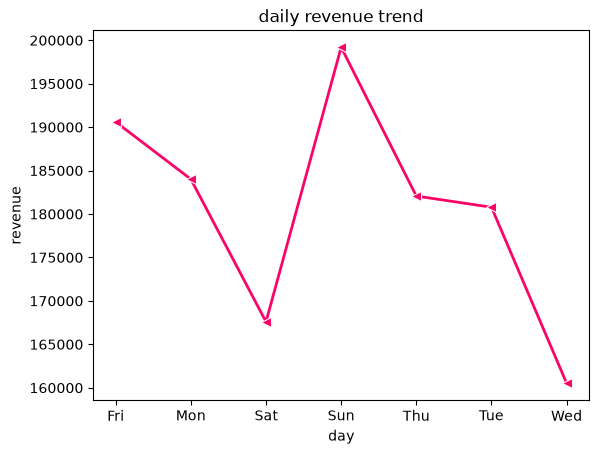

In [34]:
daily_revenue=df.groupby('DayName')['TotalPrice'].sum()
plt.Figure(figsize=(16,9))
sns.lineplot(x=daily_revenue.index,y=daily_revenue.values,marker="<",linewidth=2,markersize=7,color="#FA0567")
plt.title("daily revenue trend")
plt.xlabel("day")
plt.ylabel("revenue")

**CUSTOMER BEHAVIOR**

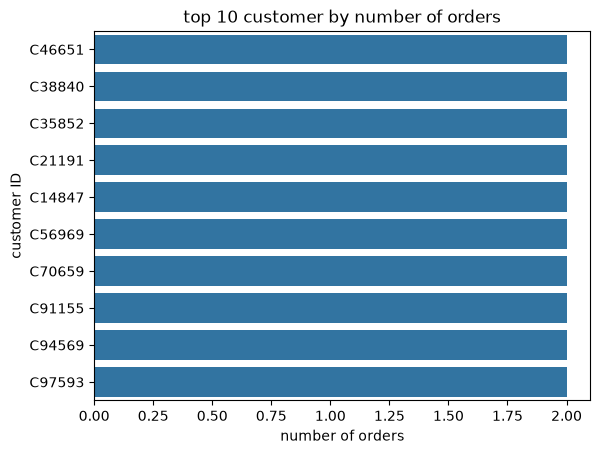

In [35]:
#NUMBER OF ORDERS BY CUSTOMER
customer_order=df.groupby('CustomerID')['OrderID'].count().sort_values(ascending=False).head(10)
plt.Figure(figsize=(16,8))
sns.barplot(x=customer_order.values,y=customer_order.index)
plt.title("top 10 customer by number of orders")
plt.xlabel("number of orders")
plt.ylabel("customer ID")
plt.show()

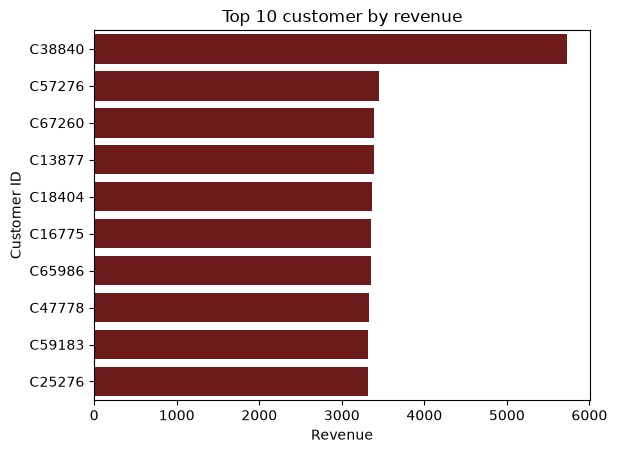

In [36]:
#customer revenue
customer_revenue=df.groupby("CustomerID")['TotalPrice'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=customer_revenue.values,y=customer_revenue.index,color="#790D0D")
plt.title("Top 10 customer by revenue")
plt.xlabel('Revenue')
plt.ylabel("Customer ID")
plt.show()

**PRODUCT PERFORMANCE**

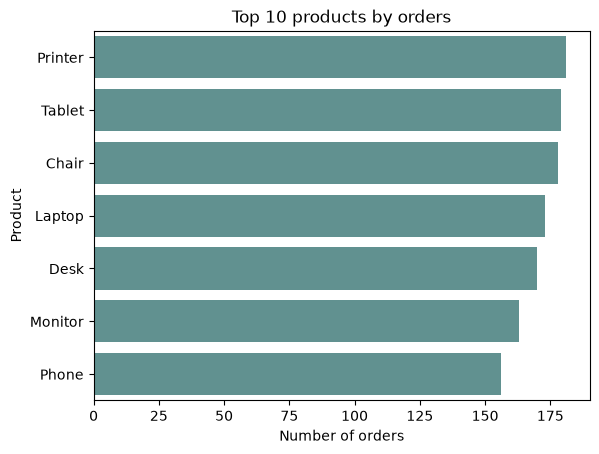

In [37]:
#TOP PRODUCT BY NUMBER OF ORDERS
top_products=df.groupby('Product')['OrderID'].count().sort_values(ascending=False).head(10)
plt.Figure(figsize=(16,8))
sns.barplot(x=top_products.values,y=top_products.index,color="#599998")
plt.title("Top 10 products by orders")
plt.xlabel("Number of orders")
plt.ylabel("Product")
plt.show()

<Axes: ylabel='Product'>

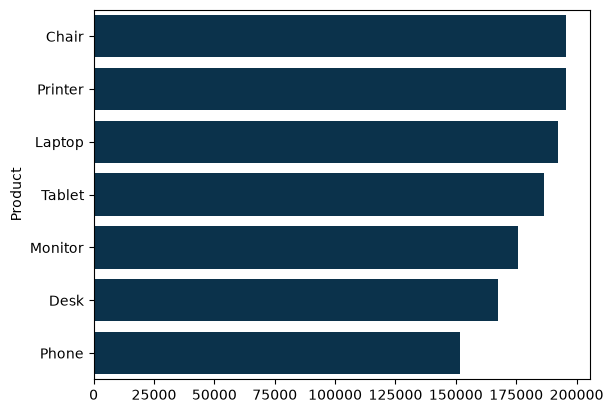

In [38]:
#TOP PRODUCTS BY REVENUE
product_revenue=df.groupby("Product")['TotalPrice'].sum().sort_values(ascending=False).nlargest(10)
plt.Figure(figsize=(16,8))
sns.barplot(x=product_revenue.values,y=product_revenue.index,color="#003456")


**PAYEMENT METHOD ANALYSIS**

Text(0.5, 1.0, 'Payment Method')

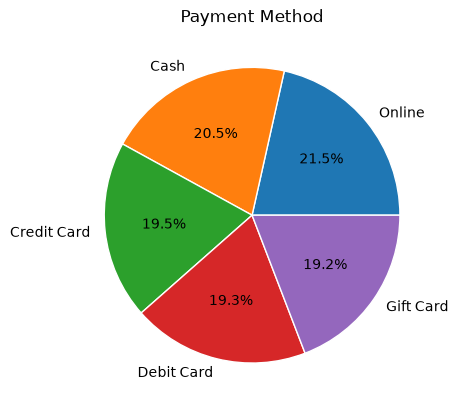

In [39]:
payment_orders=df['PaymentMethod'].value_counts()
plt.Figure(figsize=(16,8))
plt.pie(payment_orders.values,labels=payment_orders.index,autopct="%1.1f%%",wedgeprops={"edgecolor":"white",'linewidth':1})
plt.title("Payment Method")

*ORDER STATUS ANALYSIS*

Text(0.5, 1.0, 'Order Status')

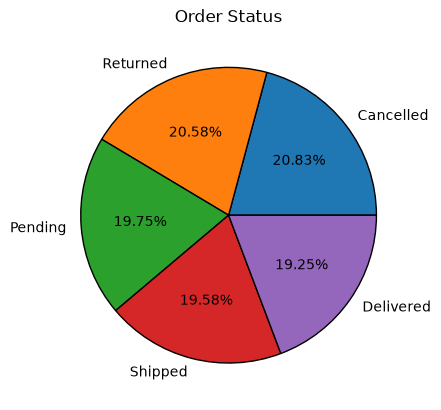

In [40]:
order_status=df['OrderStatus'].value_counts()
plt.Figure(figsize=(16,8))
plt.pie(order_status.values,labels=order_status.index,autopct="%1.2f%%",wedgeprops={"edgecolor":"black"})
plt.title("Order Status")

*REFERAL SOURCE ANALYSIS*

Text(0.5, 1.0, 'Order by referral source')

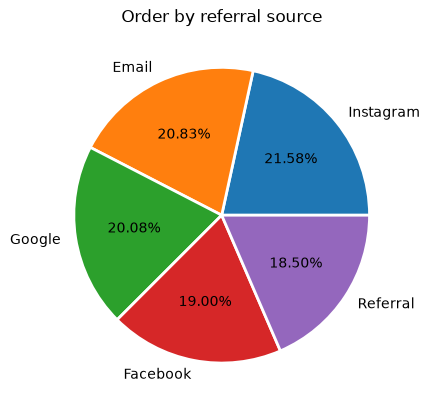

In [41]:
referal_order=df['ReferralSource'].value_counts()
plt.Figure(figsize=(16,9))
plt.pie(referal_order.values,labels=referal_order.index,autopct="%1.2f%%",wedgeprops={"edgecolor":"white","linewidth":2})
plt.title("Order by referral source")

*RELATIONSHIP ANALYSIS*

Text(0, 0.5, 'Total Price')

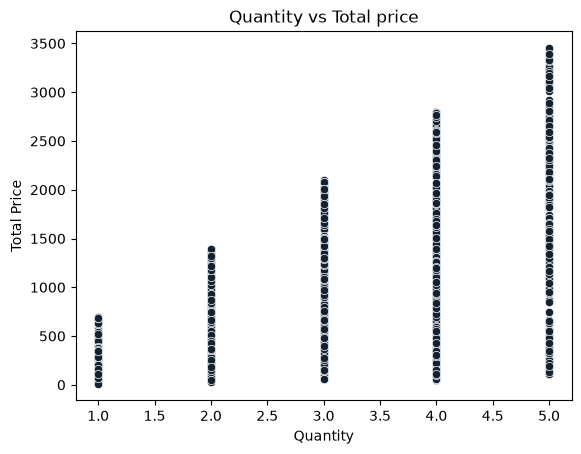

In [42]:
#QUANTITY VS TOTAL PRICE
plt.Figure(figsize=(16,9))
sns.scatterplot(x=df["Quantity"],y=df["TotalPrice"],color='#112233')
plt.title("Quantity vs Total price")
plt.xlabel("Quantity")
plt.ylabel("Total Price")

Text(0.5, 0, 'Unit Price')

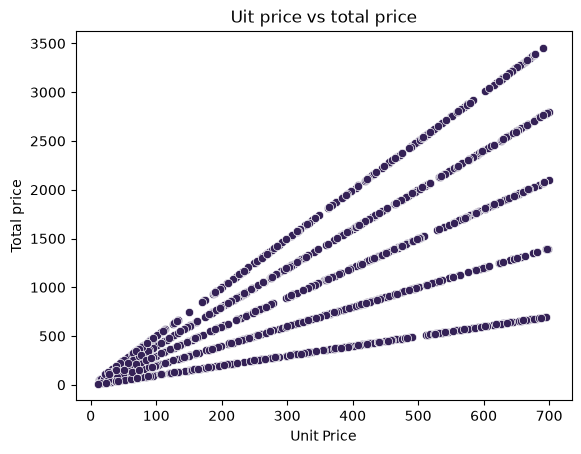

In [43]:
#Unit price vs total price
plt.Figure(figsize=(16,9))
sns.scatterplot(data=df,x='UnitPrice',y='TotalPrice',color="#342156")
plt.title("Uit price vs total price")
plt.ylabel("Total price")
plt.xlabel("Unit Price")

Text(0, 0.5, 'Unit Price')

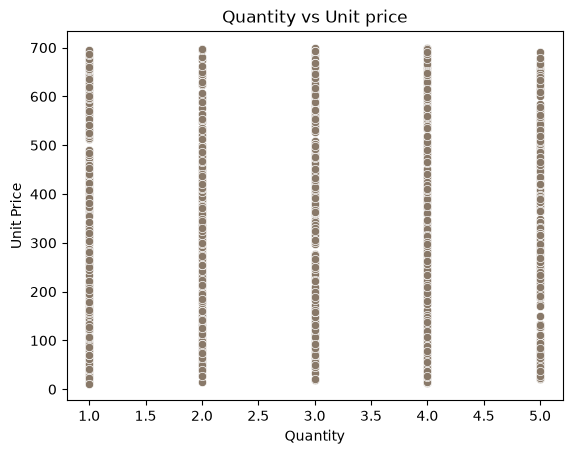

In [44]:
#Quantity vs unit price
plt.Figure(figsize=(16,9))
sns.scatterplot(data=df,x='Quantity',y='UnitPrice',color="#897969")
plt.title("Quantity vs Unit price")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")

**CORRELATION ANALYSIS**

In [45]:
numeric_columns=['Quantity','UnitPrice','ItemsInCart','TotalPrice']
correlation=df[numeric_columns].corr()
print(correlation)

             Quantity  UnitPrice  ItemsInCart  TotalPrice
Quantity     1.000000   0.014553     0.650061    0.615251
UnitPrice    0.014553   1.000000     0.000602    0.717081
ItemsInCart  0.650061   0.000602     1.000000    0.392540
TotalPrice   0.615251   0.717081     0.392540    1.000000


Text(0.5, 1.0, 'Correlation Heatmap')

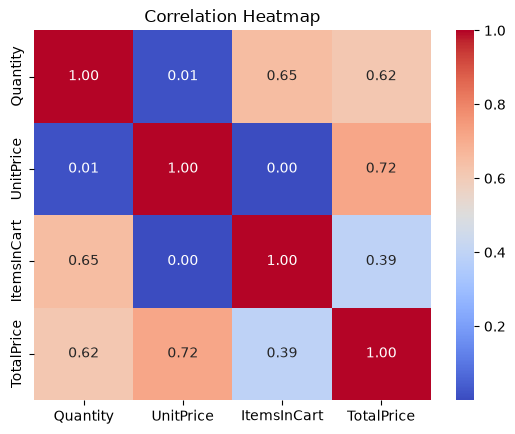

In [46]:
#Correlation Heatmap
plt.Figure(figsize=(16,9))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")

**OUTLIER DETECTION**

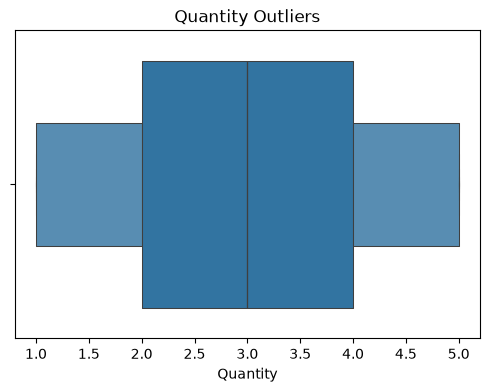

In [47]:
#Box Plot-Quantity
plt.figure(figsize=(6,4))
sns.boxenplot(x=df['Quantity'])
plt.title("Quantity Outliers")
plt.show()

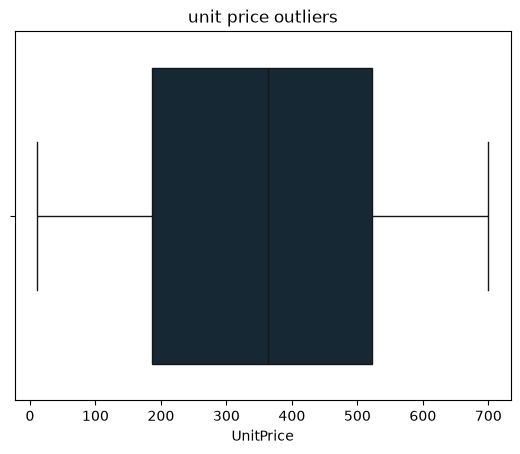

In [48]:
#box plot-unit price
plt.Figure(figsize=(6,4))
sns.boxplot(x=df['UnitPrice'],color='#102938')
plt.title("unit price outliers")
plt.show()

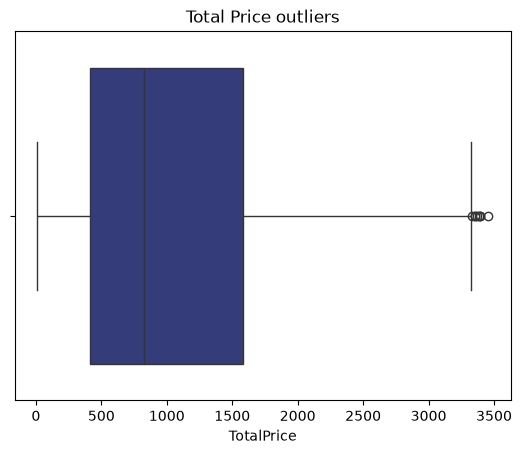

In [49]:
#Box plot-Total Price
plt.Figure(figsize=(6,4))
sns.boxplot(x=df['TotalPrice'],color='#293584')
plt.title("Total Price outliers")
plt.show()

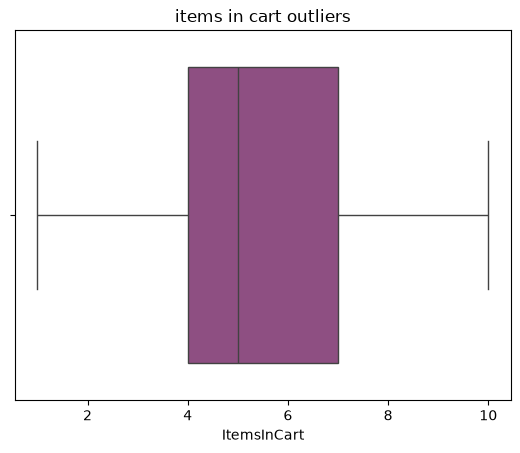

In [50]:
#Box plot-Itemsincart
plt.Figure(figsize=(6,4))
sns.boxplot(x=df['ItemsInCart'],color='#984589')
plt.title("items in cart outliers")
plt.show()

**OUTLIERS USING IQR METHOD**

In [57]:
def find_outliers(column):
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)
    IQR=Q3-Q1
    lower_limit=Q1-(1.5*IQR)
    upper_limit=Q3+(1.5*IQR)
    outliers=df[(df[column]<lower_limit)|(df[column]>upper_limit)]
    print("\ncolumn",column)
    print("Q1",Q1)
    print("Q3",Q3)
    print("IQR",IQR)
    print("LOWER LIMIT",lower_limit)
    print("UPPER LIMIT",upper_limit)
    print("Number Of Outliers:",len(outliers))
    return outliers

In [58]:
#Check outliers
Quantity_outliers=find_outliers("Quantity")
Unit_price_outliers=find_outliers("UnitPrice")
total_price_outliers=find_outliers("TotalPrice")
items_outliers=find_outliers("ItemsInCart")


column Quantity
Q1 2.0
Q3 4.0
IQR 2.0
LOWER LIMIT -1.0
UPPER LIMIT 7.0
Number Of Outliers: 0

column UnitPrice
Q1 186.0625
Q3 521.5699999999999
IQR 335.50749999999994
LOWER LIMIT -317.1987499999999
UPPER LIMIT 1024.8312499999997
Number Of Outliers: 0

column TotalPrice
Q1 410.52
Q3 1578.475
IQR 1167.955
LOWER LIMIT -1341.4125
UPPER LIMIT 3330.4075
Number Of Outliers: 8

column ItemsInCart
Q1 4.0
Q3 7.0
IQR 3.0
LOWER LIMIT -0.5
UPPER LIMIT 11.5
Number Of Outliers: 0


In [65]:
#lower and upper limt of total price column
Q1=df['TotalPrice'].quantile(0.25)
Q3=df['TotalPrice'].quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-(1.5*IQR)
upper_limit=Q3+(1.5*IQR)

In [66]:
#find 8 outliers in total price
df.loc[(df['TotalPrice']>upper_limit)|(df['TotalPrice']<lower_limit)]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,year,month,MonthName,day,DayName
107,ORD200107,2023-03-27,C16775,Printer,5,670.75,848 Main St,Gift Card,Shipped,TRK34392124,8,FREESHIP,Instagram,3353.75,2023,3,Mar,27,Mon
326,ORD200326,2024-07-01,C65986,Laptop,5,670.48,273 Main St,Gift Card,Returned,TRK98353867,5,SAVE10,Facebook,3352.40,2024,7,Jul,1,Mon
328,ORD200328,2023-02-28,C18404,Tablet,5,674.04,546 Main St,Online,Cancelled,TRK89401624,7,SAVE10,Google,3370.20,2023,2,Feb,28,Tue
469,ORD200469,2023-11-26,C13877,Chair,5,676.98,893 Main St,Cash,Cancelled,TRK17254691,5,NoCoupon,Facebook,3384.90,2023,11,Nov,26,Sun
632,ORD200632,2023-05-02,C67260,Laptop,5,678.16,463 Main St,Gift Card,Delivered,TRK38229104,7,WINTER15,Facebook,3390.80,2023,5,May,2,Tue
789,ORD200789,2023-08-17,C57276,Tablet,5,691.28,183 Main St,Online,Delivered,TRK75899752,10,SAVE10,Email,3456.40,2023,8,Aug,17,Thu
1065,ORD201065,2023-10-30,C47778,Printer,5,666.80,488 Main St,Debit Card,Delivered,TRK79504329,7,SAVE10,Referral,3334.00,2023,10,Oct,30,Mon
1122,ORD201122,2023-06-07,C38840,Monitor,5,678.19,766 Main St,Online,Returned,TRK32496970,8,NoCoupon,Facebook,3390.95,2023,6,Jun,7,Wed


In [74]:
#remove these 8 outliers from total price column 
new_df=df.loc[(df['TotalPrice']<upper_limit)&(df['TotalPrice']>lower_limit)]
#check 
print("after removing outlier",len(df))
print("before removing outlier",len(new_df))
print("total outliers",len(df)-len(new_df))
new_df

after removing outlier 1200
before removing outlier 1192
total outliers 8


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,year,month,MonthName,day,DayName
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,2023,1,Jan,4,Wed
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,2024,8,Aug,23,Fri
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2024,2,Feb,27,Tue
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,2023,10,Oct,15,Sun
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,2025,5,May,8,Thu
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,ORD201195,2024-06-20,C21126,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04,2024,6,Jun,20,Thu
1196,ORD201196,2024-03-04,C20095,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NoCoupon,Facebook,1325.06,2024,3,Mar,4,Mon
1197,ORD201197,2023-07-13,C79674,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68,2023,7,Jul,13,Thu
1198,ORD201198,2024-08-22,C64753,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08,2024,8,Aug,22,Thu


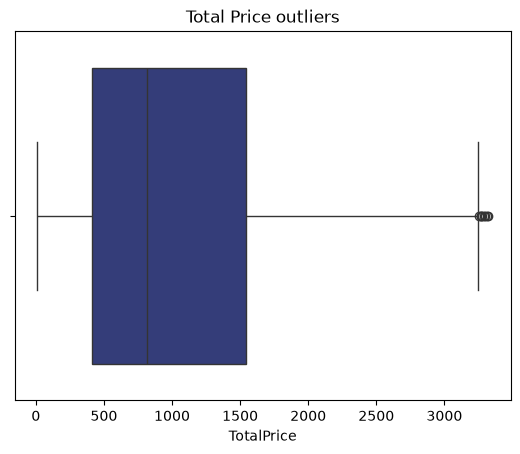

In [80]:
#Box plot-Total Price
plt.Figure(figsize=(6,4))
sns.boxplot(x=new_df['TotalPrice'],color='#293584')
plt.title("Total Price outliers")
plt.show()